# Project 3 : Chromosomes counting

Clémence ARDANT, Anthony JOURNY

## Dependancies and settings

In [1]:
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import numpy as np
from skimage import filters, segmentation, feature
from skimage.morphology import disk
from sklearn.cluster import KMeans

In [2]:
cdict1 = {
    'red': (
        (0.0, 0.0, 0.0),
        (1.0, 0.0, 0.0),
    ),
    'green': (
        (0.0, 0.0, 0.0),
        (1.0, 1.0, 0.0),
    ),
    'blue': (
        (0.0, 0.0, 0.0),
        (1.0, 0.0, 0.0),
    )
}

green_black = LinearSegmentedColormap('GreenBlack', cdict1)

cdict2 = {
    'red': (
        (0.0, 0.0, 0.0),
        (1.0, 0.0, 0.0),
    ),
    'green': (
        (0.0, 0.0, 0.0),
        (1.0, 0.0, 0.0),
    ),
    'blue': (
        (0.0, 0.0, 0.0),
        (1.0, 1.0, 0.0),
    )
}

blue_black = LinearSegmentedColormap('BlueBlack', cdict2)

## Data import

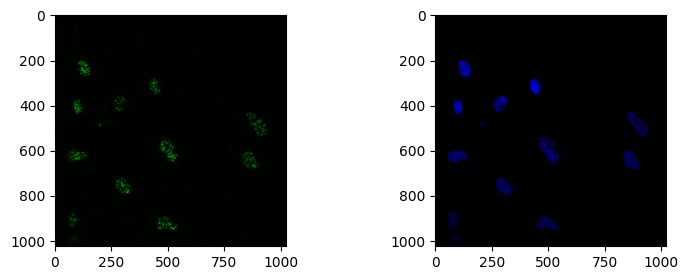

In [17]:
chromatin_green = plt.imread("Chromosomes-green.tif")
DAPI_blue = plt.imread("Chromosomes-blue.tif")

fig, axs = plt.subplots(1, 2, figsize=(9, 3))

_ = axs[0].imshow(chromatin_green, cmap=green_black)
_ = axs[1].imshow(DAPI_blue, cmap=blue_black)

## Data Exploration

In [5]:
#Verifications images:
print("chromatin_green: ", chromatin_green.shape, chromatin_green.dtype, chromatin_green.min(), chromatin_green.max())
print("DAPI_blue: ", DAPI_blue.shape, DAPI_blue.dtype, DAPI_blue.min(), DAPI_blue.max())

chromatin_green:  (1024, 1024) uint16 32 65520
DAPI_blue:  (1024, 1024) uint16 0 65520


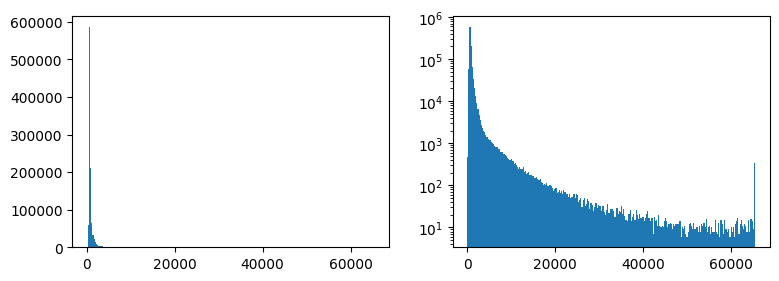

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(9, 3))
_ = axs[0].hist(chromatin_green.flatten(), bins=255, log=False)
_ = axs[1].hist(chromatin_green.flatten(), bins=255, log=True)

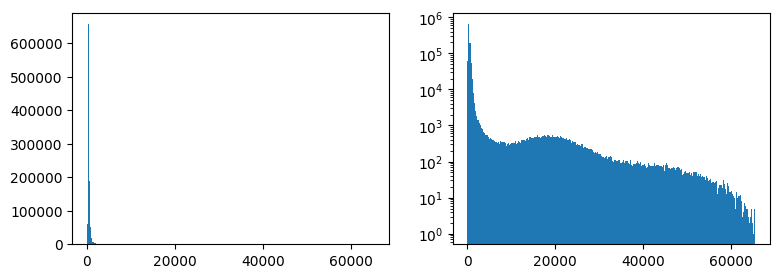

In [18]:
fig, axs = plt.subplots(1, 2, figsize=(9, 3))
_ = axs[0].hist(DAPI_blue.flatten(), bins=255, log=False)
_ = axs[1].hist(DAPI_blue.flatten(), bins=255, log=True)

[[5 3 3 ... 3 3 2]
 [6 3 3 ... 4 4 3]
 [3 4 4 ... 3 3 4]
 ...
 [3 3 2 ... 3 3 8]
 [6 5 3 ... 3 3 3]
 [2 3 2 ... 3 3 3]]


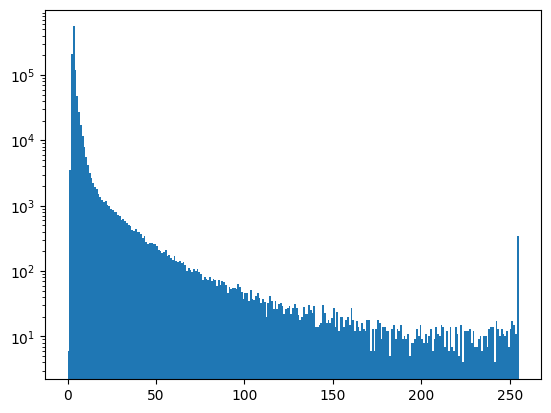

In [8]:
chromatin_green_scaled = np.around(chromatin_green.copy() / chromatin_green.max() * 255).astype(np.int64)
print(chromatin_green_scaled)
_ = plt.hist(chromatin_green_scaled.flatten(), bins=255, log=True)

66


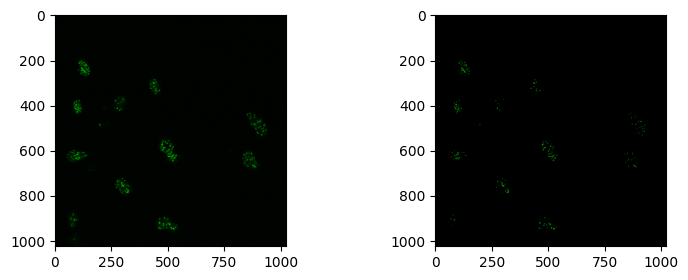

In [20]:
otsu_threshold = filters.threshold_otsu(chromatin_green_scaled)
print(otsu_threshold)
green_otsu = np.clip(chromatin_green_scaled.copy(), otsu_threshold, 255)

fig, axs = plt.subplots(1, 2, figsize=(9, 3))
_ = axs[0].imshow(chromatin_green_scaled, cmap = green_black)
_ = axs[1].imshow(green_otsu, cmap = green_black)

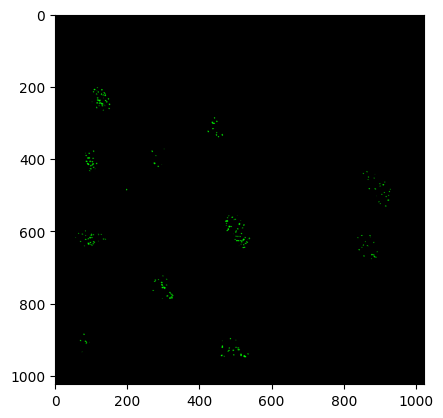

In [21]:
n_cluster = 2
X = green_otsu.reshape((-1,1))    # reshape
k_means_green = KMeans(n_cluster) # apply kmeans
k_means_green.fit(X)

X_clustered_green = k_means_green.labels_                     # extract labels for each pixel
X_clustered_green = X_clustered_green.reshape(green_otsu.shape)   # reshape
_ = plt.imshow(X_clustered_green, cmap = green_black)